In [1]:
from mylib.statistic_test import *

code_id = "0870 - Map Rearrangement and Swing"
loc = join(figpath, "Dsp", code_id)
mkdir(loc)

d:\Softwares\Anaconda2025\envs\maze\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


        D:\Data\FinalResults\Dsp\0870 - Map Rearrangement and Swing is already existed!


False

# Fig. 3h Sudden Map Rearrangement 

42


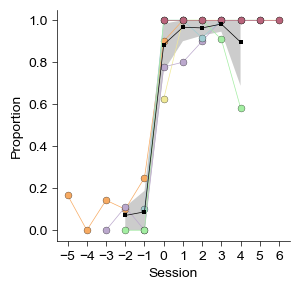

  Mean: 0.0875, STD: 0.10231690964840563, Max: 0.25, Min: 0.0, Median: 0.05, df: 3
  Mean: 0.8837962962962962, STD: 0.1408237145764364, Max: 1.0, Min: 0.625, Median: 0.95, df: 5


In [15]:
if exists(join(figdata, f"{code_id} [Map Rearrangement].pkl")) == False:
    data = {
        "MiceID": np.concatenate([np.repeat(mouse, 7) for mouse in [10212, 10224, 10227, 10232, 10275, 10276]]),
        "Session": [-5, -4, -3, -2, -1, 0, 1,
                    0, 1, 2, 3, 4, 5, 6,
                    -3, -2, -1, 0, 1, 2, 3,
                    -1, 0, 1, 2, 3, 4, 5,
                    -2, -1, 0, 1, 2, 3, 4,
                    0, 1, 2, 3, 4, 5, 6
                    ],
        "Proportion": [1/6, 0/6, 1/7, 1/10, 1/4, 9/10, 10/10,
                    5/8, 1, 1, 1, 1, 1, 1,
                    0/8, 1/9, 0/9, 7/9, 8/10, 9/10, 1,
                    1/10, 1, 1, 11/12, 1, 1, 1,
                    0/10, 0/12, 10/10, 11/11, 11/11, 10/11, 7/12,
                    10/10, 11/11, 11/11, 11/11, 10/10, 12/12, 11/11],
        # Transition Time / (Lap Num - 1)
        "Transition Frequency": [1, 0, 2, 1, 3, 2, 0,
                                1, 0, 0, 0, 0, 0, 0,
                                0, 2, 0, 4, 3, 2, 0,
                                2, 0, 0, 2, 0, 0, 0,
                                0, 0, 2, 0, 0, 2, 4,
                                0, 0, 0, 0, 0, 0, 0],
        "Lap Number-1": [6-1, 6-1, 7-1, 10-1, 10-1, 8-1, 10-1, 
            8-1, 9-1, 10-1, 10-1, 13-1, 10-1, 10-1,
            8-1, 9-1, 9-1, 9-1, 10-1, 10-1, 9-1,
            10-1, 10-1, 10-1, 11-1, 12-1, 12-1, 14-1,
            10-1, 12-1, 10-1, 11-1, 11-1, 11-1, 12-1,
            10-1, 11-1, 11-1, 11-1, 10-1, 12-1, 11-1
            ],
    }
    for k in data.keys():
        data[k] = np.asarray(data[k])
    # These data are manually counted from Figure 3C and related extended Figures.

    with open(join(figdata, f"{code_id} [Map Rearrangement].pkl"), 'wb') as f:
        pickle.dump(data, f)
    
    D = pd.DataFrame(data)
    D.to_excel(join(figdata, f"{code_id} [Map Rearrangement].xlsx"), index=False)
    print(len(D))
else:
    with open(join(figdata, f"{code_id} [Map Rearrangement].pkl"), 'rb') as f:
        data = pickle.load(f)

fig = plt.figure(figsize=(3, 3))
SubData = SubDict(data, data.keys(), np.where(np.isin(data['Session'], [-2, -1, 0, 1, 2, 3, 4]))[0])
ax = Clear_Axes(plt.axes(), close_spines=['top', 'right'], ifxticks=True, ifyticks=True)
for i in range(6):
    ax.plot(
        data['Session'][i*7:(i+1)*7],
        data['Proportion'][i*7:(i+1)*7],
        linewidth=0.5,
        marker='o',
        markersize=5,
        markeredgewidth=0.2,
        markeredgecolor='k',
        color=MicePaletteDSP[i],
    )
sns.lineplot(
    x = 'Session',
    y = 'Proportion',
    data = SubData,
    linewidth = 0.5,
    marker='s',
    markeredgewidth=0,
    markersize=3,
    color = 'k',
    err_kws={"edgecolor": None},
    ax = ax,
    legend=False
)
ax.set_xticks(np.arange(-5, 7))
plt.savefig(join(loc, "Map Switching Proportion.png"), dpi=600)
plt.savefig(join(loc, "Map Switching Proportion.svg"), dpi=600)
plt.show()

print_estimator(SubData['Proportion'][SubData['Session'] == -1])
print_estimator(SubData['Proportion'][SubData['Session'] == 0])

# Fig. 3i - Map swing frequency

<Axes: xlabel='Session', ylabel='Swing Count'>

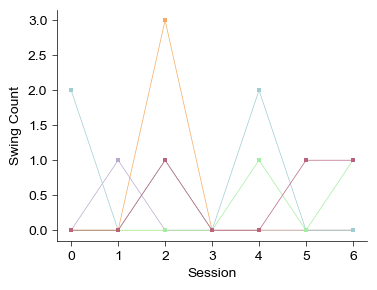

In [ ]:
if exists(join(figdata, f"{code_id} [Map Swing Frequency].pkl")) == False:
    MapSwingFrequency = {
        "MiceID": np.concatenate([np.repeat(mouse, 7) for mouse in [10212, 10224, 10227, 10232, 10275, 10276]]),
        "Session": np.concatenate([np.arange(7) for _ in range(6)]),
        "Swing Count": [
            0, 0, 3, 0, 0, 0, 0,
            0, 0, 0, 0, 0, 0, 0,
            0, 1, 0, 0, 0, 0, 0,
            2, 0, 1, 0, 2, 0, 0,
            0, 0, 0, 0, 1, 0, 1,
            0, 0, 1, 0, 0, 1, 1
        ]
    }
    
    for k in MapSwingFrequency.keys():
        MapSwingFrequency[k] = np.asarray(MapSwingFrequency[k])
    
    with open(join(figdata, f"{code_id} [Map Swing Frequency].pkl"), 'wb') as f:
        pickle.dump(MapSwingFrequency, f)
else:
    with open(join(figdata, f"{code_id} [Map Swing Frequency].pkl"), 'rb') as f:
        MapSwingFrequency = pickle.load(f)
    
fig = plt.figure(figsize=(4, 3))
ax = Clear_Axes(plt.axes(), close_spines=['top', 'right'], ifxticks=True, ifyticks=True)
sns.lineplot(
    x = 'Session',
    y = 'Swing Count',
    data = MapSwingFrequency,
    linewidth = 0.5,
    marker='s',
    markeredgewidth=0,
    markersize=3,
    color = 'k',
    err_kws={"edgecolor": None},
    ax = ax,
    legend=False
)

In [ ]:
apvc_dir = join(figdata, "Dsp", "0877 - Revisit Stability", "Retrieval Results")

if exists(join(figdata, f"{code_id} [PVC on Pre-Final Segment].pkl")) == False:
    CorrPFS = {
        'MiceID': [],
        'Session': [],
        'Bin': [],
        'PVC': [],
        'Type': []
    }
    
    session_convertor = {
        10212: np.arange(-5, 2),
        10224: np.arange(7),
        10227: np.arange(-3, 4),
        10232: np.arange(-1, 6)
    }
    
    for mouse in [10212, 10224, 10227, 10232]:
        for s in tqdm(range(7)):
            pvc_corr, bins, pvc_ctrl = get_pvc(mouse, s)
            CorrPFS['MiceID'].append(np.repeat(mouse, len(pvc_corr)*2))
            CorrPFS['Session'].append(np.repeat(session_convertor[mouse][s], len(pvc_corr)*2))
            CorrPFS['Bin'].append(np.concatenate([bins, bins]))
            CorrPFS['PVC'].append(np.concatenate([pvc_corr, pvc_ctrl]))
            CorrPFS['Type'].append(np.concatenate([np.repeat('PVC', len(pvc_corr)), np.repeat('Control', len(pvc_ctrl))]))
    
    for k in CorrPFS.keys():
        CorrPFS[k] = np.concatenate(CorrPFS[k])
        
    with open(join(figdata, f"{code_id} [PVC on Pre-Final Segment].pkl"), 'wb') as f:
        pickle.dump(CorrPFS, f)
        
    CorrPFSD = pd.DataFrame(CorrPFS)
    CorrPFSD.to_excel(join(figdata, f"{code_id} [PVC on Pre-Final Segment].xlsx"), index=False)
    print(len(CorrPFSD))
else:
    with open(join(figdata, f"{code_id} [PVC on Pre-Final Segment].pkl"), 'rb') as f:
        CorrPFSD = pickle.load(f)

fig = plt.figure(figsize=(6, 2))
SubData = SubDict(CorrPFSD, CorrPFSD.keys(), np.where((np.abs(CorrPFSD['Session']) <= 1))[0])
SubData['hue'] = np.array([f"{SubData['Type'][i]}-{SubData['Session'][i]}" for i in range(len(SubData['Type']))])
ax = Clear_Axes(plt.axes(), close_spines=['top', 'right'], ifxticks=True, ifyticks=True)
sns.barplot(
    x=SubData['Bin'], 
    y=SubData['PVC'], 
    hue=SubData['hue'], 
    hue_order=['PVC--1', 'PVC-0', 'PVC-1', 'Control--1', 'Control-0', 'Control-1'],
    ax=ax, 
    palette=sns.color_palette("Greens", 3) + sns.color_palette("Blues", 3),
    capsize=0.5,
    edgecolor='black',
    linewidth=0.5,
    err_kws={'linewidth': 0.5, 'color': 'k'}
)
ax.set_ylim(-0.05, 1)
ax.set_yticks(np.linspace(0, 1, 6))
plt.savefig(join(loc, "PVC on Pre-Final Segment.png"), dpi=600)
plt.savefig(join(loc, "PVC on Pre-Final Segment.svg"), dpi=600)
plt.show()

for b in range(4, 11):
    SubData = SubDict(CorrPFSD, CorrPFSD.keys(), np.where((CorrPFSD['Bin'] == b))[0])
    x0 = SubDict(SubData, SubData.keys(), np.where((SubData['Type'] == 'PVC')&(SubData['Session'] == -1))[0])
    x1 = SubDict(SubData, SubData.keys(), np.where((SubData['Type'] == 'PVC')&(SubData['Session'] == 0))[0])
    x2 = SubDict(SubData, SubData.keys(), np.where((SubData['Type'] == 'PVC')&(SubData['Session'] == 1))[0])
    x3 = SubDict(SubData, SubData.keys(), np.where((SubData['Type'] == 'Control')&(SubData['Session'] == -1))[0])
    x4 = SubDict(SubData, SubData.keys(), np.where((SubData['Type'] == 'Control')&(SubData['Session'] == 0))[0])
    x5 = SubDict(SubData, SubData.keys(), np.where((SubData['Type'] == 'Control')&(SubData['Session'] == 1))[0])
    
    print(f"Bin {b}:")
    print(f"  PVC: {f_oneway(x0['PVC'], x1['PVC'], x2['PVC'])}")
    print(f"  Control: {f_oneway(x3['PVC'], x4['PVC'], x5['PVC'])}", end='\n\n')